# Task 38: SVM, k-NN, and Decision Tree Comparison

Compare held-out metrics and visualize three manually implemented decision regions over age and maximum heart rate. The two-feature display aids interpretation and is not a clinical tool.

Unique records: 302
               accuracy  precision  recall     f1
Linear SVM        0.707      0.721   0.756  0.738
k-NN (k=7)        0.667      0.711   0.659  0.684
Decision tree     0.640      0.694   0.610  0.649


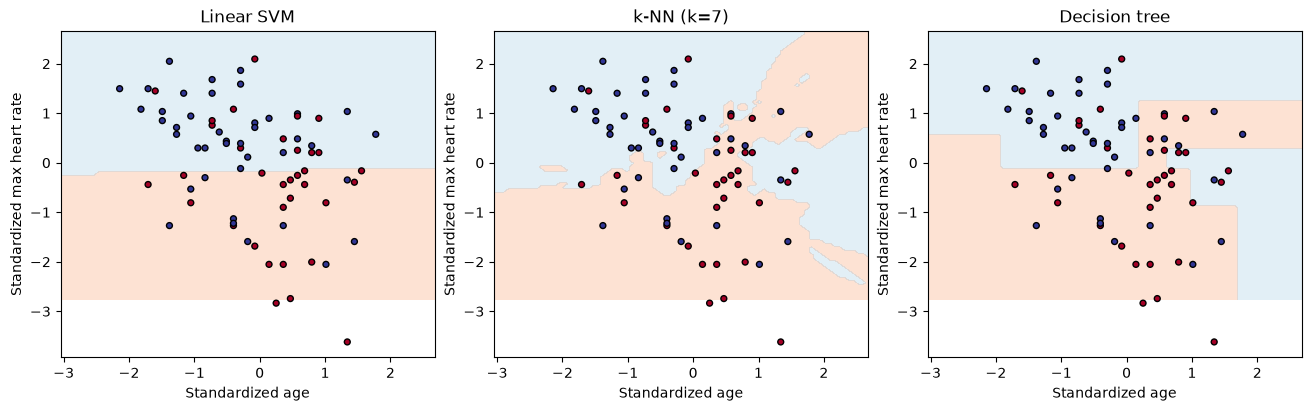

Interpretation: SVM gives a compact linear margin; k-NN can bend around local patterns but scales at prediction time; trees are readable, axis-aligned rules but can be unstable. These two features omit relevant clinical information and are not diagnostic.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_options = [Path('heart.csv'), Path('Task_38_Model_Comparison_Decision_Boundaries/heart.csv'), Path('Heart_Disease_Tasks/Task_38_Model_Comparison_Decision_Boundaries/heart.csv')]
csv_path = next(path for path in csv_options if path.is_file())
data = pd.read_csv(csv_path).drop_duplicates().reset_index(drop=True)
feature_names = ['age', 'thalach']
X = data[feature_names].to_numpy(float)
y = data['target'].to_numpy(int)
rng = np.random.default_rng(38)
train_parts, test_parts = [], []
for label in np.unique(y):
    indices = np.flatnonzero(y == label)
    rng.shuffle(indices)
    split = int(round(0.75 * len(indices)))
    train_parts.append(indices[:split]); test_parts.append(indices[split:])
train_idx, test_idx = np.concatenate(train_parts), np.concatenate(test_parts)
rng.shuffle(train_idx); rng.shuffle(test_idx)
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
mean, scale = X_train.mean(axis=0), X_train.std(axis=0)
scale[scale == 0] = 1.0
X_train, X_test = (X_train - mean) / scale, (X_test - mean) / scale


def score_metrics(actual, predicted):
    tp = int(np.sum((actual == 1) & (predicted == 1)))
    tn = int(np.sum((actual == 0) & (predicted == 0)))
    fp = int(np.sum((actual == 0) & (predicted == 1)))
    fn = int(np.sum((actual == 1) & (predicted == 0)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {'accuracy': (tp + tn) / len(actual), 'precision': precision, 'recall': recall, 'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0}


def train_linear_svm(x, labels, epochs=900, rate=0.02, regularization=0.02):
    signed = np.where(labels == 1, 1.0, -1.0)
    weights, bias = np.zeros(x.shape[1]), 0.0
    for epoch in range(epochs):
        active = signed * (x @ weights + bias) < 1
        step = rate / (1 + 0.002 * epoch)
        weights -= step * (regularization * weights - x[active].T @ signed[active] / len(labels))
        bias += step * signed[active].sum() / len(labels)
    return lambda points: (points @ weights + bias >= 0).astype(int)


def knn_predict(train_x, train_y, points, k=7):
    predictions = []
    for point in points:
        distances = np.sqrt(np.sum((train_x - point) ** 2, axis=1))
        nearest = np.argsort(distances, kind='stable')[:k]
        values, counts = np.unique(train_y[nearest], return_counts=True)
        tied = values[counts == counts.max()]
        if len(tied) > 1:
            totals = [(distances[nearest][train_y[nearest] == label].sum(), label) for label in tied]
            predictions.append(int(min(totals)[1]))
        else:
            predictions.append(int(tied[0]))
    return np.array(predictions)


def train_tree(train_x, train_y, depth=0, max_depth=4):
    counts = np.bincount(train_y, minlength=2)
    node = {'prediction': int(np.argmax(counts))}
    if depth >= max_depth or len(np.unique(train_y)) < 2 or len(train_y) < 8:
        return node
    parent = 1 - np.sum((counts / len(train_y)) ** 2)
    best = None
    for feature in range(train_x.shape[1]):
        values = np.unique(train_x[:, feature])
        for threshold in (values[:-1] + values[1:]) / 2:
            left = train_x[:, feature] <= threshold
            if not left.any() or left.all():
                continue
            gain = parent - left.mean() * (1 - np.sum((np.bincount(train_y[left], minlength=2) / left.sum()) ** 2)) - (~left).mean() * (1 - np.sum((np.bincount(train_y[~left], minlength=2) / (~left).sum()) ** 2))
            if best is None or gain > best[0]:
                best = (gain, feature, threshold, left)
    if best is None or best[0] <= 0:
        return node
    _, feature, threshold, left = best
    node.update({'feature': feature, 'threshold': threshold, 'left': train_tree(train_x[left], train_y[left], depth + 1, max_depth), 'right': train_tree(train_x[~left], train_y[~left], depth + 1, max_depth)})
    return node


def predict_tree(points, root):
    output = []
    for point in points:
        node = root
        while 'feature' in node:
            node = node['left'] if point[node['feature']] <= node['threshold'] else node['right']
        output.append(node['prediction'])
    return np.array(output)


svm = train_linear_svm(X_train, y_train)
tree = train_tree(X_train, y_train)
models = {
    'Linear SVM': lambda points: svm(points),
    'k-NN (k=7)': lambda points: knn_predict(X_train, y_train, points, 7),
    'Decision tree': lambda points: predict_tree(points, tree),
}
metric_table = pd.DataFrame({name: score_metrics(y_test, predict(X_test)) for name, predict in models.items()}).T
print('Unique records:', len(data))
print(metric_table.round(3))

axis_x = np.linspace(X_train[:, 0].min() - 0.25, X_train[:, 0].max() + 0.25, 80)
axis_y = np.linspace(X_train[:, 1].min() - 0.25, X_train[:, 1].max() + 0.25, 80)
grid_x, grid_y = np.meshgrid(axis_x, axis_y)
grid = np.column_stack([grid_x.ravel(), grid_y.ravel()])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, (name, predict) in zip(axes, models.items()):
    region = predict(grid).reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, region, levels=[-0.5, 0.5, 1.5], alpha=0.25, cmap='RdYlBu')
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='RdYlBu', edgecolors='black', s=18)
    ax.set_title(name); ax.set_xlabel('Standardized age'); ax.set_ylabel('Standardized max heart rate')
plt.show()
print('Interpretation: SVM gives a compact linear margin; k-NN can bend around local patterns but scales at prediction time; trees are readable, axis-aligned rules but can be unstable. These two features omit relevant clinical information and are not diagnostic.')